# Klasifikacija toksičnih tvitova

In [1]:
import re
import html
import unicodedata
import string

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from wordcloud import WordCloud

import nltk
from nltk.tokenize import word_tokenize
from nltk.corpus import stopwords, wordnet
from nltk.stem import PorterStemmer, SnowballStemmer, WordNetLemmatizer
from nltk import pos_tag

import emoji
from spellchecker import SpellChecker

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB, GaussianNB
from sklearn.svm import LinearSVC
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

import gensim
from gensim.models import Word2Vec

import warnings
warnings.filterwarnings('ignore')

nltk.download('punkt', quiet=True)
nltk.download('punkt_tab', quiet=True)
nltk.download('stopwords', quiet=True)
nltk.download('wordnet', quiet=True)
nltk.download('averaged_perceptron_tagger', quiet=True)
nltk.download('averaged_perceptron_tagger_eng', quiet=True)

sns.set_theme(style='whitegrid', palette='muted')
pd.set_option('display.max_colwidth', 120)

Sve biblioteke uspešno učitane.


In [6]:
sns.set_theme(palette="pastel")

## Učitavanje dataseta

In [2]:
df = pd.read_csv('twitter_toxic_tweets.csv')
print(df.shape)
df.head()

(31962, 3)


,id,label,tweet
0,1,0,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
1,2,0,@user @user thanks for #lyft credit i can't use cause they don't offer wheelchair vans in pdx. #disapointed #gett...
2,3,0,bihday your majesty
3,4,0,#model i love u take with u all the time in urð±!!! ðððð ð¦ð¦ð¦
4,5,0,factsguide: society now #motivation


In [3]:
df.info()
print()
print('Distribucija klasa:')
print(df['label'].value_counts())
print(df['label'].value_counts(normalize=True).mul(100).round(1).astype(str) + '%')

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 31962 entries, 0 to 31961
Data columns (total 3 columns):
 #   Column  Non-Null Count  Dtype 
---  ------  --------------  ----- 
 0   id      31962 non-null  int64 
 1   label   31962 non-null  int64 
 2   tweet   31962 non-null  object
dtypes: int64(2), object(1)
memory usage: 749.2+ KB

Distribucija klasa:
label
0    29720
1     2242
Name: count, dtype: int64
label
0    93.0%
1     7.0%
Name: proportion, dtype: object


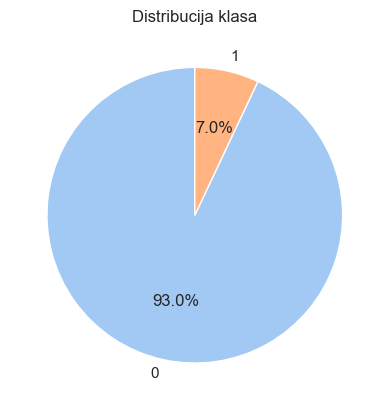

In [8]:
sentiment_counts = df['label'].value_counts()
labels = sentiment_counts.index
sizes = sentiment_counts.values

plt.pie(
    sizes,
    labels=labels,
    autopct='%1.1f%%',
    startangle=90
)
plt.title("Distribucija klasa")
plt.show()

## Kvalitet tekstualnih podataka

### Dužina dokumenata

Dužina tvita meri se na dva načina: brojem karaktera i brojem tokena (reči). Distribucija dužine može se razlikovati između klasa - toksični tvitovi mogu biti kraći i direktniji, ili duži zbog upotrebe više uvreda.

In [10]:
df['char_count'] = df['tweet'].str.len()
df['token_count'] = df['tweet'].apply(lambda x: len(word_tokenize(str(x))))

stats = df.groupby('label')[['char_count', 'token_count']].agg(['min', 'max', 'mean', 'median'])
stats.columns = ['_'.join(c) for c in stats.columns]
stats.index = stats.index.map({0: 'Non-toxic', 1: 'Toxic'})
stats.round(1).T

label,Non-toxic,Toxic
char_count_min,11.0,12.0
char_count_max,274.0,152.0
char_count_mean,84.3,90.2
char_count_median,88.0,96.0
token_count_min,3.0,3.0
token_count_max,121.0,39.0
token_count_mean,17.9,19.0
token_count_median,18.0,19.0


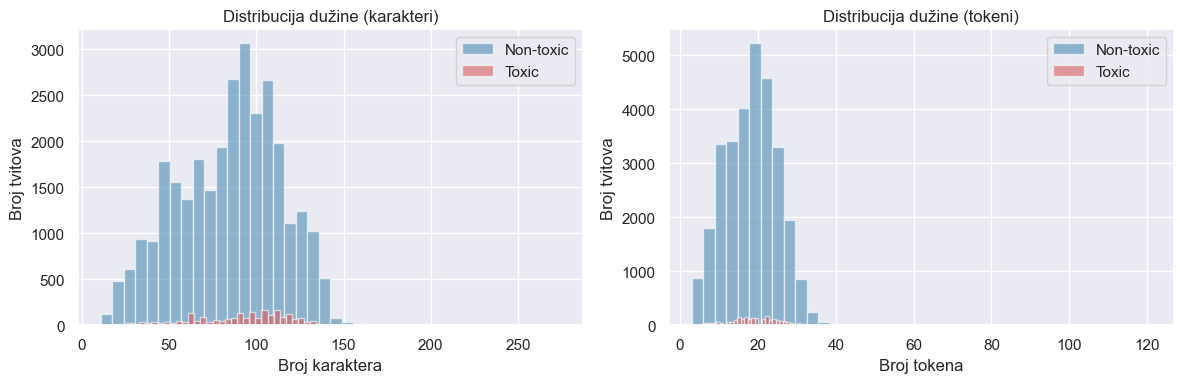

In [12]:
label_map = {0: 'Non-toxic', 1: 'Toxic'}
colors = {'Non-toxic': '#4C8BB5', 'Toxic': '#D95F5F'}

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for label_val, label_name in label_map.items():
    subset = df[df['label'] == label_val]
    axes[0].hist(subset['char_count'], bins=40, alpha=0.6, label=label_name, color=colors[label_name])
    axes[1].hist(subset['token_count'], bins=40, alpha=0.6, label=label_name, color=colors[label_name])

axes[0].set_title('Distribucija dužine (karakteri)')
axes[0].set_xlabel('Broj karaktera')
axes[0].set_ylabel('Broj tvitova')
axes[0].legend()

axes[1].set_title('Distribucija dužine (tokeni)')
axes[1].set_xlabel('Broj tokena')
axes[1].set_ylabel('Broj tvitova')
axes[1].legend()

plt.tight_layout()
plt.show()

### Veličina vokabulara

Veličina vokabulara označava broj jedinstvenih tokena u korpusu. Poređenje vokabulara između klasa može otkriti da li toksični tvitovi koriste specifičan skup reči.

In [13]:
def get_vocab(texts):
    tokens = [t for text in texts for t in word_tokenize(str(text).lower())]
    return set(tokens), tokens

toxic_texts    = df[df['label'] == 1]['tweet']
nontoxic_texts = df[df['label'] == 0]['tweet']

vocab_all,     tokens_all     = get_vocab(df['tweet'])
vocab_toxic,   tokens_toxic   = get_vocab(toxic_texts)
vocab_nontox,  tokens_nontox  = get_vocab(nontoxic_texts)

vocab_stats = pd.DataFrame({
    'Korpus':             ['Ceo dataset', 'Toxic',          'Non-toxic'],
    'Ukupno tokena':      [len(tokens_all), len(tokens_toxic), len(tokens_nontox)],
    'Jedinstvenih tokena':[len(vocab_all),  len(vocab_toxic),  len(vocab_nontox)],
})
vocab_stats['Ekskluzivni tokeni'] = [
    '-',
    len(vocab_toxic - vocab_nontox),
    len(vocab_nontox - vocab_toxic)
]
vocab_stats

,Korpus,Ukupno tokena,Jedinstvenih tokena,Ekskluzivni tokeni
0,Ceo dataset,575990,47109,-
1,Toxic,42693,6401,2552
2,Non-toxic,533297,44557,40708


### Leksička raznovrsnost

Tvitovi su kratki dokumenti, što automatski povećava TTR jer se reči retko ponavljaju unutar jednog tvita. Zbog toga se koristi **STTR (Standardized TTR)** koji računa prosečni TTR na prozorima fiksne veličine.

In [17]:
def ttr(tokens):
    return len(set(tokens)) / len(tokens) if tokens else 0

def sttr(tokens, window=100):
    chunks = [tokens[i:i+window] for i in range(0, len(tokens) - window + 1, window)]
    return np.mean([ttr(c) for c in chunks]) if chunks else 0

results = []
for label_val, label_name in [(None, 'Ceo dataset'), (1, 'Toxic'), (0, 'Non-toxic')]:
    texts = df['tweet'] if label_val is None else df[df['label'] == label_val]['tweet']
    tokens = [t for text in texts for t in word_tokenize(str(text).lower())]
    results.append({
        'Korpus': label_name,
        'TTR':  round(ttr(tokens), 4),
        'STTR (w=100)': round(sttr(tokens, 100), 4)
    })

pd.DataFrame(results)

,Korpus,TTR,STTR (w=100)
0,Ceo dataset,0.0818,0.7014
1,Toxic,0.1499,0.7013
2,Non-toxic,0.0836,0.7000


### Šum u tekstu

Tvitovi sadrže karakteristične vrste šuma koje nisu prisutne u standardnim tekstualnim korpusima: URL-ovi, `@mentions`, `#hashtags`, HTML entiteti, specijalni karakteri i emoji simboli. Ovde ih identifikujemo i vizualizujemo pre bilo kakve predobrade.

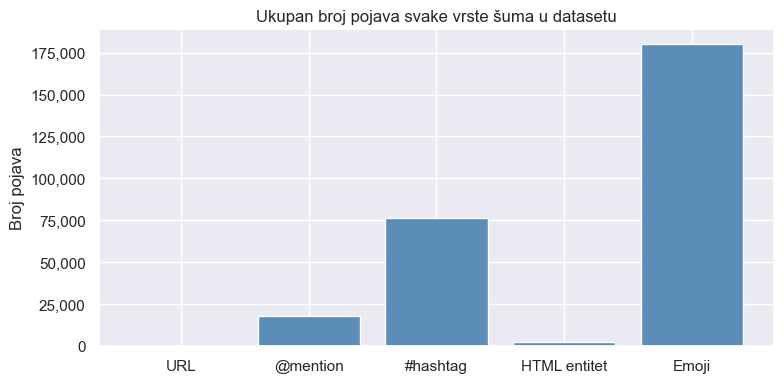


Brojevi pojava:
  URL                 : 6
  @mention            : 17,571
  #hashtag            : 76,296
  HTML entitet        : 2,256
  Emoji               : 179,862


In [18]:
noise_patterns = {
    'URL':            r'https?://\S+|www\.\S+',
    '@mention':       r'@\w+',
    '#hashtag':       r'#\w+',
    'HTML entitet':   r'&[a-z]+;|&#\d+;',
    'Emoji':          r'[^\w\s,\.!?\'"-]',
}

noise_counts = {name: df['tweet'].str.count(pat).sum() for name, pat in noise_patterns.items()}

fig, ax = plt.subplots(figsize=(8, 4))
ax.bar(noise_counts.keys(), noise_counts.values(), color='#5B8DB8')
ax.set_title('Ukupan broj pojava svake vrste šuma u datasetu')
ax.set_ylabel('Broj pojava')
ax.yaxis.set_major_formatter(mticker.FuncFormatter(lambda x, _: f'{int(x):,}'))
plt.tight_layout()
plt.show()

print('\nBrojevi pojava:')
for k, v in noise_counts.items():
    print(f'  {k:20s}: {v:,}')

In [19]:
# Konkretni primeri svake vrste šuma iz dataseta
examples = {}
for name, pat in noise_patterns.items():
    mask = df['tweet'].str.contains(pat, regex=True, na=False)
    examples[name] = df[mask]['tweet'].iloc[0] if mask.any() else 'N/A'

ex_df = pd.DataFrame({'Vrsta šuma': examples.keys(), 'Primer tvita': examples.values()})
ex_df

,Vrsta šuma,Primer tvita
0,URL,#fly #and #better #with #us #buranus #www.flybcc.com #call #7/24 #airbroker #flightâ¦
1,@mention,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
2,#hashtag,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run
3,HTML entitet,product of the day: happy man #wine tool who's it's the #weekend? time to open up &amp; drink up!
4,Emoji,@user when a father is dysfunctional and is so selfish he drags his kids into his dysfunction. #run


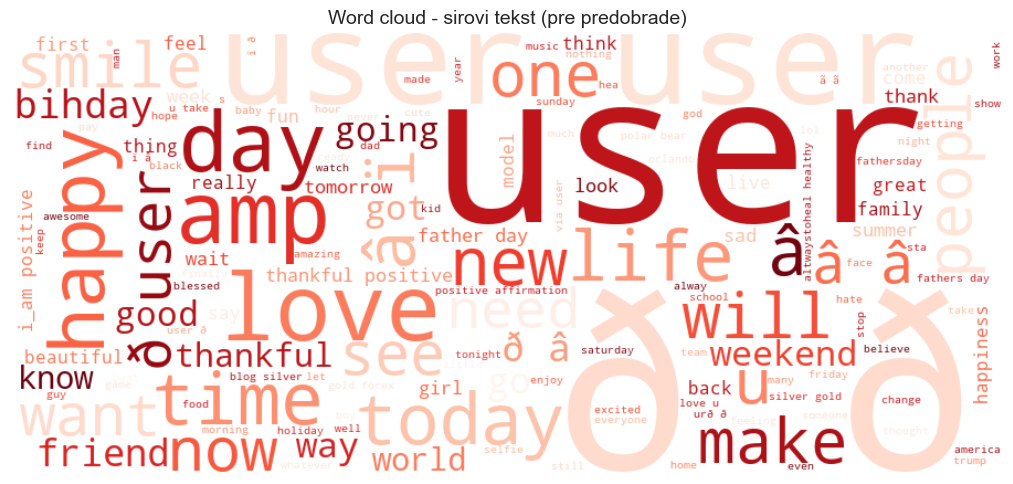

In [21]:
raw_text = ' '.join(df['tweet'].dropna().astype(str).tolist())

wc = WordCloud(width=900, height=400, background_color='white',
               max_words=150, colormap='Reds').generate(raw_text)

plt.figure(figsize=(12, 5))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word cloud - sirovi tekst (pre predobrade)', fontsize=14)
plt.tight_layout()
plt.show()